# Study 9: old fit vs new fit — coherence fields and log likelihood

Two posterior-median parameter sets for the study-9 joint fit:

| model | fit on | source | ls | mu_0 | sigma | beta |
|---|---|---|---|---|---|---|
| **old** | **pilot** data (`data/pilots/study9.csv`, Oct 2025, n=402) | `model-study9-vbmc-laplace-beta.ipynb` @ `8d87b50` (renamed to `study9-fit/fitted-feature-shapes.npz` in `95a37c4`, since overwritten) | 0.205 | -0.397 | 0.782 | 16.04 |
| **new** | **prereg** data (`data/study9_prereg.csv`, Jun–Jul 2026, n=419) | current `fitted-feature-shapes.npz` (seeded refit) | 0.978 | +0.006 | 0.526 | 0.907 |

The model code is effectively unchanged between the two fits: same priors, VBMC box, speaker and kernel, and at
the old theta the current code reproduces the old saved linking shapes exactly. **The difference comes from the
dataset.** Sections 1–5 score both parameter sets on the prereg data; section 6 repeats the scoring on the pilot data.

Both are scored with the **same current likelihood code** (per-feature Beta-mixture linking shapes profiled out
at each theta, Laplace marginal over the latent coherence), so any difference comes from the parameters alone.

Metrics:
- **log Z (joint)** = log p(utterances, ratings | theta): the quantity VBMC fits.
- **log p(ratings | utterances, theta)**: log Z minus the ratings-free log Z. This scores only the rating data.
  It matters here because beta changes how probable the training utterances are, so the joint log Z can move
  through the utterance term without any change in how well the ratings fit.
- **log prior** and **log joint** (log Z + log prior): the unnormalized posterior density VBMC saw.

The parameter values are hard-coded below, so the notebook only needs `inference.py`, the geometry pickle, and the data CSV.

In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")
import sys; sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import inference as inf

DATA_CSV = '../../data/study9_prereg.csv'

# posterior medians (ls, mu_0, sigma, beta)
THETA = {
    # committed fitted-feature-shapes.npz at 65f41e5 (95% CI: ls [0.16, 0.28], beta [7.0, 27.0])
    'old': (0.20526066465922216, -0.39730651435898356, 0.7815199274312206, 16.035191727776876),
    # current fitted-feature-shapes.npz (95% CI: ls [0.67, 2.95], beta [0.40, 1.58])
    'new': (0.9777498763730996, 0.0059589420404462246, 0.5256339466322824, 0.9069409561002713),
}
COLORS = {'old': '#c0392b', 'new': '#2c6fbb'}

geom = inf.load_geometry()
J = geom['J']
responses_cond, _ = inf.load_responses(DATA_CSV)
emp_cond = {c: np.array(responses_cond[c]).mean(0) for c in inf.CONDITIONS}
N_cond   = {c: int(responses_cond[c].shape[0]) for c in inf.CONDITIONS}
N_tot    = sum(N_cond.values())
print("conditions:", N_cond, " J =", J, " total ratings =", N_tot * J)

conditions: {'physical': 99, 'diet': 98, 'personality': 103, 'heterogeneous': 101}  J = 15  total ratings = 6015


## 1. Log likelihood of the data under each parameter set

In [2]:
def log_prior(theta):
    ls, mu0, sig, beta = theta
    return (inf.log_prior_ls(np.log(ls)) + inf.log_prior_mu(mu0)
            + inf.log_prior_sigma(np.log(sig)) + inf.log_prior_beta(np.log(beta)))

def score(theta):
    # per-condition joint log Z and ratings-free log Z, shapes profiled at theta
    ls, mu0, sig, beta = theta
    _, shapes, cond_data = inf.total_log_lik_free_shapes(
        geom, responses_cond, ls, mu0, sig, beta_speaker=beta, return_shapes=True)
    free = inf._ratings_free_cond_data(geom)
    rows = []
    for c in inf.CONDITIONS:
        lz, _, ok      = inf.laplace_log_Z(cond_data[c], ls, mu0, sig, beta)
        lz_free, _, ok2 = inf.laplace_log_Z(free[c], ls, mu0, sig, beta)
        rows.append({'condition': c, 'logZ_joint': lz, 'logZ_utterances': lz_free,
                     'loglik_ratings': lz - lz_free, 'laplace_ok': ok and ok2})
    return pd.DataFrame(rows).set_index('condition'), shapes

per_cond, SHAPES = {}, {}
for m, th in THETA.items():
    per_cond[m], SHAPES[m] = score(th)

summary = pd.DataFrame({
    m: {'log Z (joint)':              per_cond[m]['logZ_joint'].sum(),
        'log p(utterances)':          per_cond[m]['logZ_utterances'].sum(),
        'log p(ratings | utterances)': per_cond[m]['loglik_ratings'].sum(),
        'log prior':                  log_prior(THETA[m]),
        'log joint (logZ + prior)':   per_cond[m]['logZ_joint'].sum() + log_prior(THETA[m])}
    for m in THETA})
summary['new - old'] = summary['new'] - summary['old']
display(summary.round(2))

d_rat = summary.loc['log p(ratings | utterances)', 'new - old']
print(f"ratings log-lik difference (new - old): {d_rat:+.2f} nats"
      f"  = {d_rat / N_tot:+.3f} nats/participant  = {d_rat / (N_tot * J):+.4f} nats/rating")
print("all Laplace modes converged:", all(per_cond[m]['laplace_ok'].all() for m in THETA))

,old,new,new - old
log Z (joint),945.30,988.75,43.46
log p(utterances),-34.02,-41.42,-7.40
log p(ratings | utterances),979.31,1030.17,50.85
log prior,-1.87,-1.37,0.51
log joint (logZ + prior),943.42,987.39,43.96


ratings log-lik difference (new - old): +50.85 nats  = +0.127 nats/participant  = +0.0085 nats/rating
all Laplace modes converged: True


In [3]:
# per-condition breakdown of the ratings log-lik
bd = pd.DataFrame({f'{m}': per_cond[m]['loglik_ratings'] for m in THETA})
bd['new - old'] = bd['new'] - bd['old']
bd['n'] = pd.Series(N_cond)
bd['(new - old) / n'] = bd['new - old'] / bd['n']
display(bd.round(2))

,old,new,new - old,n,(new - old) / n
condition,,,,,
physical,341.22,353.57,12.34,99,0.12
diet,297.21,305.99,8.78,98,0.09
personality,181.43,198.91,17.49,103,0.17
heterogeneous,159.45,171.70,12.25,101,0.12


## 2. Coherence fields

Ratings-free coherence field P(kind-linked) over the 2d embedding: GP + RSA speaker conditioned only on each
condition's training utterances. Top row is old, bottom row is new, and both use the same 0–1 colour scale.
Dark dots are training features. Ringed dots are test features, filled with the condition's mean rating
(same colour map).

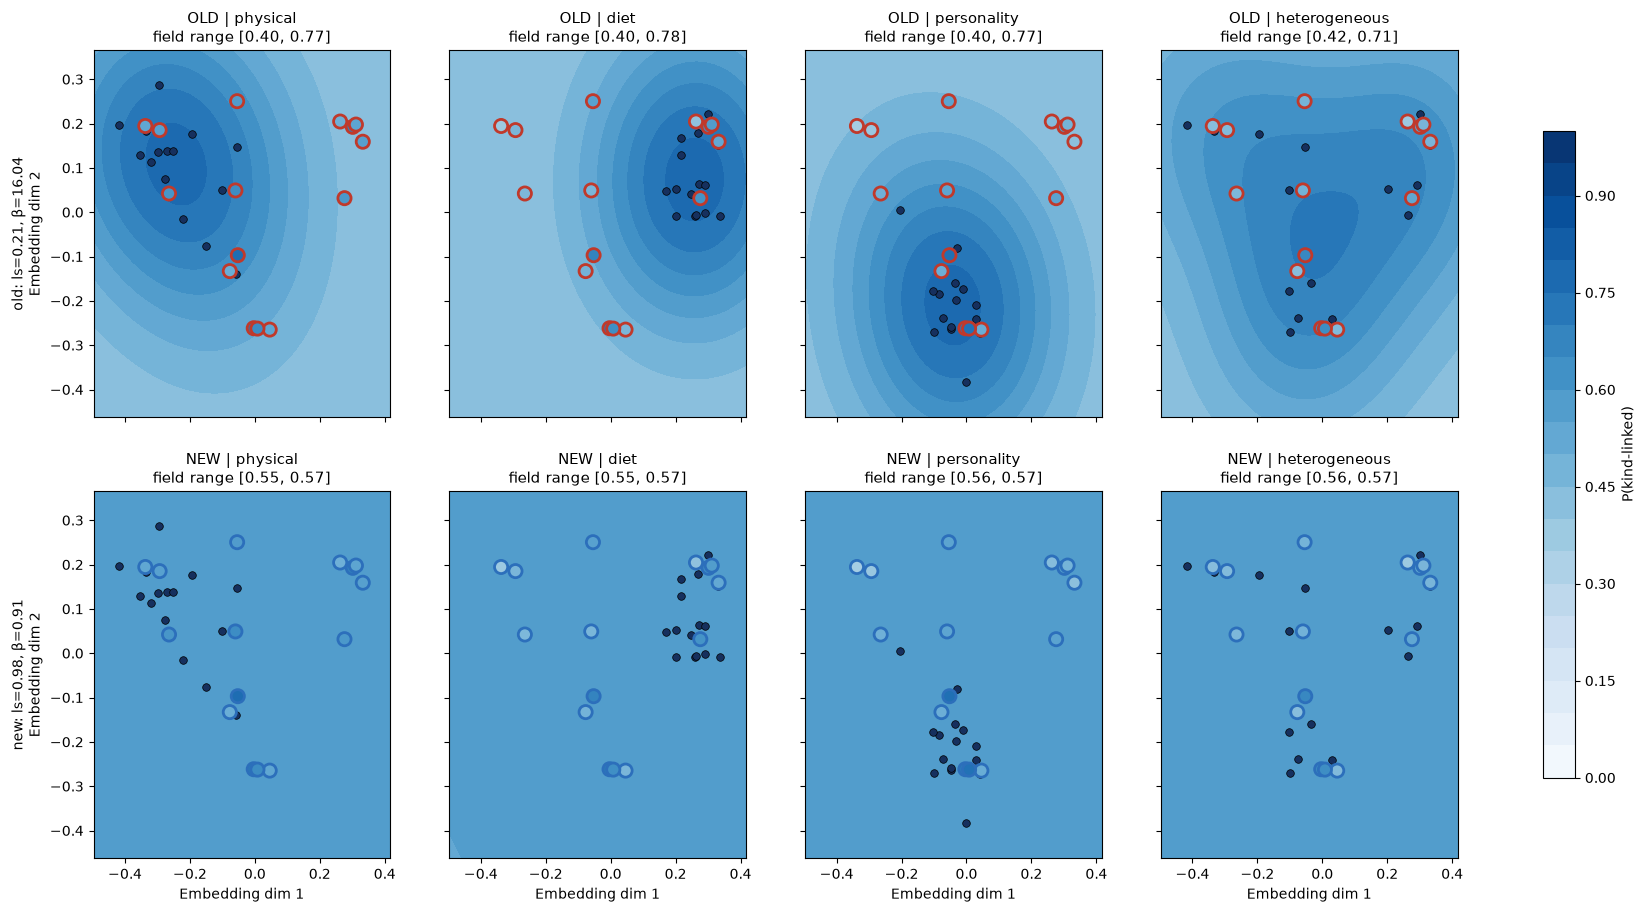

In [4]:
all_x = np.vstack([np.array(geom['x_test'])] + [np.array(geom['x_train_cond'][c]) for c in inf.CONDITIONS])
pad = 0.08
(x_lo, y_lo), (x_hi, y_hi) = all_x.min(0) - pad, all_x.max(0) + pad
gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 80), np.linspace(y_lo, y_hi, 80))
X_grid = np.column_stack([gx.ravel(), gy.ravel()])
x_test = np.array(geom['x_test'])

FIELD, PZ1_TEST = {}, {}
for m, (ls, mu0, sig, beta) in THETA.items():
    for c in inf.CONDITIONS:
        FIELD[m, c]    = inf.gp_coherence_field(geom, c, ls, mu0, sig, X_grid, beta_speaker=beta).reshape(gx.shape)
        PZ1_TEST[m, c] = inf.gp_coherence_field(geom, c, ls, mu0, sig, x_test, beta_speaker=beta)

levels = np.linspace(0, 1, 21)
fig, axes = plt.subplots(2, 4, figsize=(22, 10.5), sharex=True, sharey=True)
for i, m in enumerate(THETA):
    ls, mu0, sig, beta = THETA[m]
    for k, c in enumerate(inf.CONDITIONS):
        ax = axes[i, k]
        cs = ax.contourf(gx, gy, FIELD[m, c], levels=levels, cmap='Blues', vmin=0, vmax=1)
        x_tr = np.array(geom['x_train_cond'][c])
        ax.scatter(x_tr[:, 0], x_tr[:, 1], s=30, color='#16305e', edgecolor='k', lw=0.5, zorder=3)
        ax.scatter(x_test[:, 0], x_test[:, 1], s=90, c=emp_cond[c], cmap='Blues', vmin=0, vmax=1,
                   edgecolor=COLORS[m], linewidth=2, zorder=4)
        f = FIELD[m, c]
        ax.set_title(f"{m.upper()} | {c}\nfield range [{f.min():.2f}, {f.max():.2f}]", fontsize=11)
        if k == 0:
            ax.set_ylabel(f"{m}: ls={ls:.2f}, β={beta:.2f}\nEmbedding dim 2")
        if i == 1:
            ax.set_xlabel('Embedding dim 1')
fig.colorbar(cs, ax=axes, shrink=0.8, label='P(kind-linked)')
plt.show()

### Difference map (new − old)

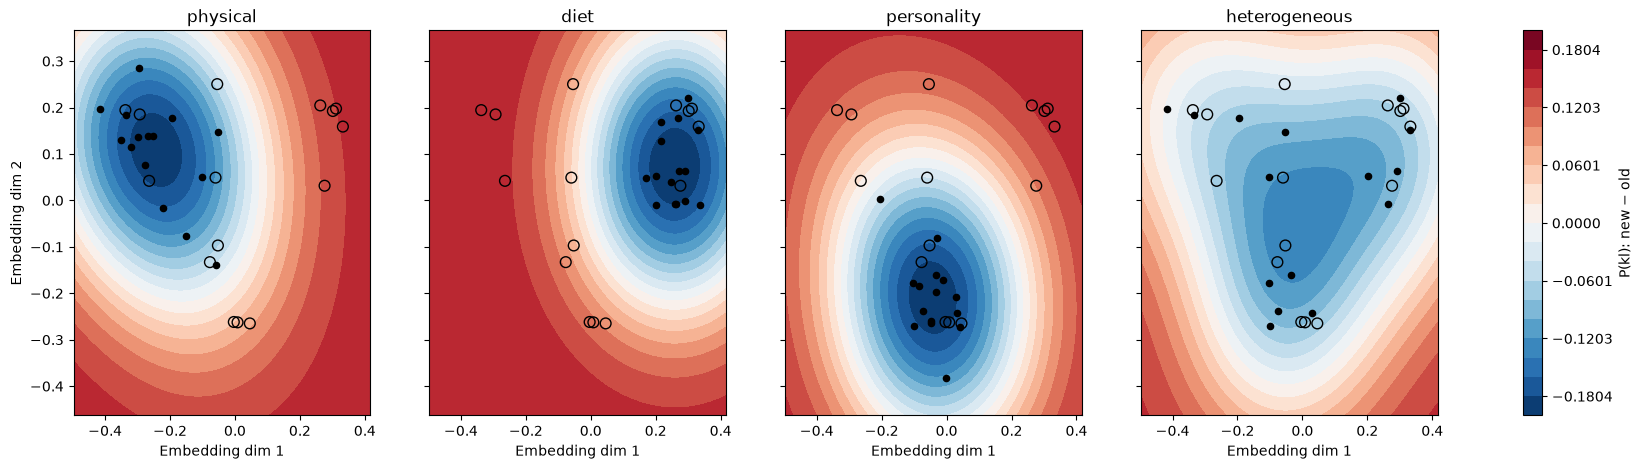

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True)
vmax = max(np.abs(FIELD['new', c] - FIELD['old', c]).max() for c in inf.CONDITIONS)
for ax, c in zip(axes, inf.CONDITIONS):
    cs = ax.contourf(gx, gy, FIELD['new', c] - FIELD['old', c], levels=np.linspace(-vmax, vmax, 21),
                     cmap='RdBu_r')
    x_tr = np.array(geom['x_train_cond'][c])
    ax.scatter(x_tr[:, 0], x_tr[:, 1], s=20, color='k', zorder=3)
    ax.scatter(x_test[:, 0], x_test[:, 1], s=60, facecolor='none', edgecolor='k', zorder=3)
    ax.set_title(c); ax.set_xlabel('Embedding dim 1')
axes[0].set_ylabel('Embedding dim 2')
fig.colorbar(cs, ax=axes, label='P(kl): new − old')
plt.show()

## 3. Coherence at the test features vs the data

Left panels show ratings-free coherence at each test feature against that feature's mean rating in the condition.
The right panel shows each model's implied mean rating against the empirical mean for every (condition, feature)
cell. The implied rating is `pz1·mean_kl + (1−pz1)·mean_nkl`, using that model's own profiled linking shapes.

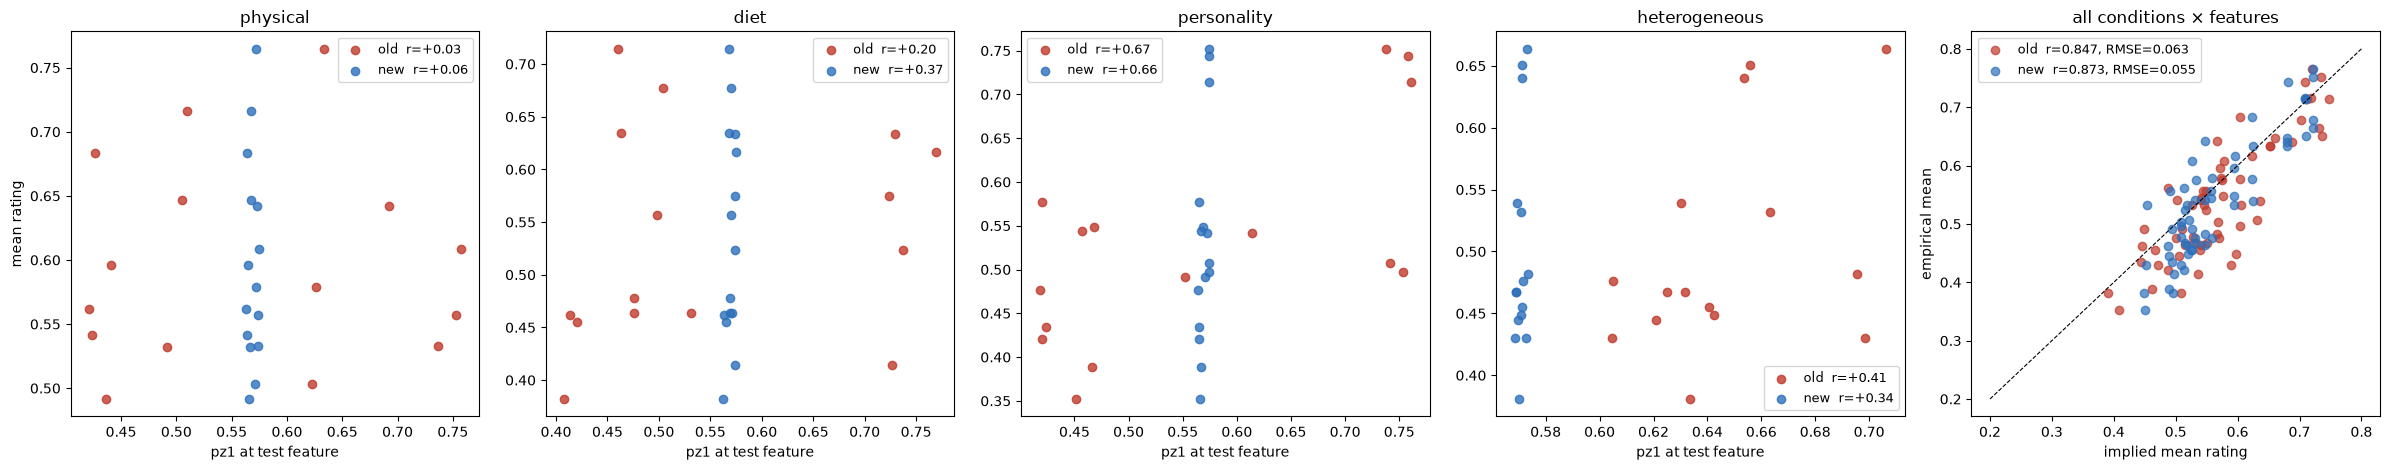

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.8))
for ax, c in zip(axes[:4], inf.CONDITIONS):
    for m in THETA:
        p = PZ1_TEST[m, c]
        r = np.corrcoef(p, emp_cond[c])[0, 1] if np.ptp(p) > 1e-3 else np.nan
        ax.scatter(p, emp_cond[c], color=COLORS[m], label=f"{m}  r={r:+.2f}", alpha=0.8)
    ax.set_title(c); ax.set_xlabel('pz1 at test feature'); ax.legend(fontsize=9)
axes[0].set_ylabel('mean rating')

ax = axes[4]
emp_all = np.concatenate([emp_cond[c] for c in inf.CONDITIONS])
for m in THETA:
    sh = SHAPES[m]
    mkl, mnkl = sh[:, 0] / (sh[:, 0] + sh[:, 1]), sh[:, 2] / (sh[:, 2] + sh[:, 3])
    pred = np.concatenate([PZ1_TEST[m, c] * mkl + (1 - PZ1_TEST[m, c]) * mnkl for c in inf.CONDITIONS])
    r = np.corrcoef(pred, emp_all)[0, 1]
    rmse = np.sqrt(np.mean((pred - emp_all) ** 2))
    ax.scatter(pred, emp_all, color=COLORS[m], alpha=0.7, label=f"{m}  r={r:.3f}, RMSE={rmse:.3f}")
lim = [min(emp_all.min(), 0.2), max(emp_all.max(), 0.8)]
ax.plot(lim, lim, 'k--', lw=0.8)
ax.set_xlabel('implied mean rating'); ax.set_ylabel('empirical mean')
ax.set_title('all conditions × features'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 4. Likelihood along the straight line from old to new

Interpolates linearly in the fitting coordinates `[log ls, mu_0, log sigma, log beta]` (t=0 is old, t=1 is new)
and scores each point. A dip in the middle means two separate modes. A monotone curve means the old fit was
simply short of the optimum. This takes about 1–2 minutes.

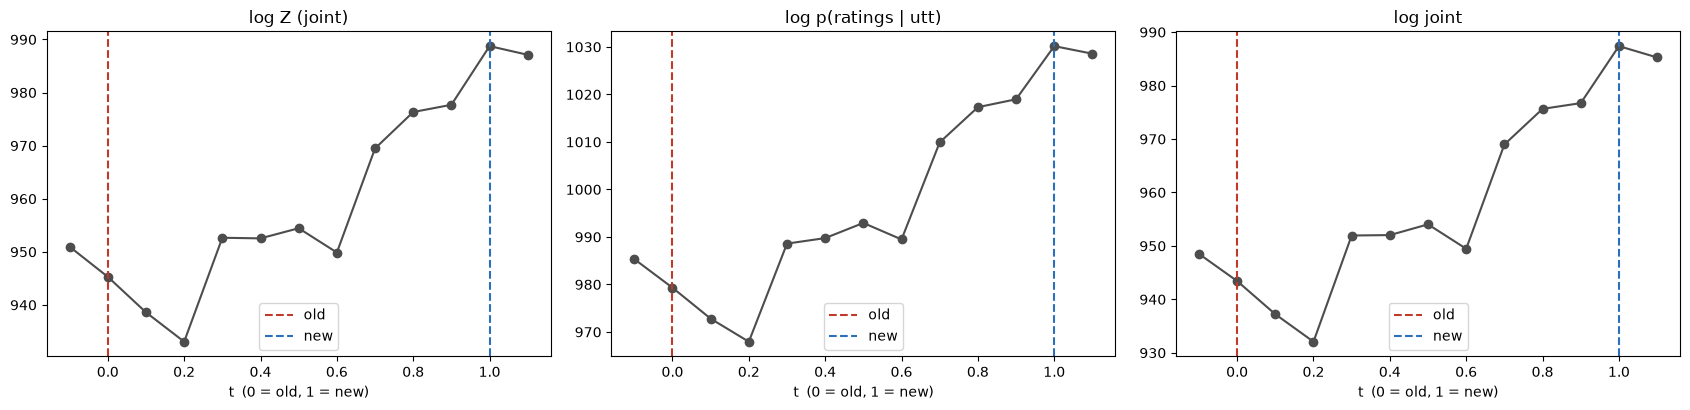

,t,ls,beta,log Z (joint),log p(ratings | utt),log joint
0,-0.1,0.176,21.371,950.964,985.342,948.510
1,0.0,0.205,16.035,945.295,979.314,943.423
2,0.1,0.240,12.032,938.602,972.803,937.215
3,0.2,0.280,9.028,933.071,967.949,932.072
4,0.3,0.328,6.774,952.652,988.598,951.946
5,0.4,0.383,5.082,952.536,989.759,952.024
6,0.5,0.448,3.814,954.446,992.947,954.034
7,0.6,0.524,2.861,949.872,989.474,949.463
8,0.7,0.612,2.147,969.479,1009.909,968.975
9,0.8,0.716,1.611,976.336,1017.311,975.642


In [7]:
def to_phi(th):  ls, mu0, sig, beta = th; return np.array([np.log(ls), mu0, np.log(sig), np.log(beta)])
def from_phi(p): return (float(np.exp(p[0])), float(p[1]), float(np.exp(p[2])), float(np.exp(p[3])))

p_old, p_new = to_phi(THETA['old']), to_phi(THETA['new'])
ts = np.linspace(-0.1, 1.1, 13)
path = []
for t in ts:
    th = from_phi((1 - t) * p_old + t * p_new)
    pc, _ = score(th)
    path.append({'t': t, 'ls': th[0], 'beta': th[3],
                 'log Z (joint)': pc['logZ_joint'].sum(),
                 'log p(ratings | utt)': pc['loglik_ratings'].sum(),
                 'log joint': pc['logZ_joint'].sum() + log_prior(th)})
path = pd.DataFrame(path)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col in zip(axes, ['log Z (joint)', 'log p(ratings | utt)', 'log joint']):
    ax.plot(path['t'], path[col], 'o-', color='0.3')
    for m, t0 in [('old', 0.0), ('new', 1.0)]:
        ax.axvline(t0, color=COLORS[m], ls='--', label=m)
    ax.set_xlabel('t  (0 = old, 1 = new)'); ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()
display(path.round(3))

## 5. Summary

In [8]:
print(summary.round(2).to_string())
print()
for c in inf.CONDITIONS:
    d = np.abs(FIELD['new', c] - FIELD['old', c])
    print(f"{c:>13}: max |Δfield| = {d.max():.3f}, mean |Δfield| = {d.mean():.3f}, "
          f"max |Δpz1 @ test| = {np.abs(PZ1_TEST['new', c] - PZ1_TEST['old', c]).max():.3f}")

                                old      new  new - old
log Z (joint)                945.30   988.75      43.46
log p(utterances)            -34.02   -41.42      -7.40
log p(ratings | utterances)  979.31  1030.17      50.85
log prior                     -1.87    -1.37       0.51
log joint (logZ + prior)     943.42   987.39      43.96

     physical: max |Δfield| = 0.196, mean |Δfield| = 0.100, max |Δpz1 @ test| = 0.183
         diet: max |Δfield| = 0.200, mean |Δfield| = 0.115, max |Δpz1 @ test| = 0.194
  personality: max |Δfield| = 0.198, mean |Δfield| = 0.096, max |Δpz1 @ test| = 0.186
heterogeneous: max |Δfield| = 0.143, mean |Δfield| = 0.062, max |Δpz1 @ test| = 0.133


## 6. Cross-check on the pilot data (what the old fit was fit to)

If each parameter set wins on its own dataset, the data drove the difference, not a code change or VBMC luck.
Each cell scores one parameter set on one dataset with `inf.total_log_lik_free_shapes` (the same objective VBMC
optimizes, linking shapes re-fit to that dataset); the ratings-only metric uses `inf.conditional_ratings_log_lik`.

In [9]:
resp_pilot, _ = inf.load_responses('../../data/pilots/study9.csv')
rows = {}
for dname, resp in [('pilot', resp_pilot), ('prereg', responses_cond)]:
    for m, th in THETA.items():
        ll = inf.total_log_lik_free_shapes(geom, resp, *th[:3], beta_speaker=th[3])
        rows[(dname, m)] = {'log Z (joint)': ll,
                            'log p(ratings | utterances)': inf.conditional_ratings_log_lik(geom, resp, *th[:3], beta_speaker=th[3]),
                            'log joint': ll + log_prior(th)}
cross = pd.DataFrame(rows).T
cross.index.names = ['data', 'params']

# 2x2 view per metric: rows = dataset, columns = parameter set
col_label = {m: f"{m} params (ls {THETA[m][0]:.2f}, β {THETA[m][3]:.2f})" for m in THETA}
for metric in cross.columns:
    tbl = cross[metric].unstack('params')[list(THETA)].rename(columns=col_label)
    tbl['new - old'] = tbl.iloc[:, 1] - tbl.iloc[:, 0]
    print(f"\n{metric}")
    display(tbl.round(1))


log Z (joint)


params,"old params (ls 0.21, β 16.04)","new params (ls 0.98, β 0.91)",new - old
data,,,
pilot,914.4,901.5,-12.9
prereg,945.3,988.8,43.5



log p(ratings | utterances)


params,"old params (ls 0.21, β 16.04)","new params (ls 0.98, β 0.91)",new - old
data,,,
pilot,948.4,942.9,-5.5
prereg,979.3,1030.2,50.9



log joint


params,"old params (ls 0.21, β 16.04)","new params (ls 0.98, β 0.91)",new - old
data,,,
pilot,912.5,900.2,-12.4
prereg,943.4,987.4,44.0


## 7. Is the new fit the global optimum? Profile likelihood over (length scale, β)

Checks whether a better solution exists anywhere in the VBMC box, especially at **low length scale and high β**.
Computed by `profile_study9_ls_beta.py` (about 20 min on 10 processes) and loaded here from
`results/study9-fit/profile-ls-beta.npz`.

- **Grid:** 13 × 13 log-spaced (ls, β) points covering the VBMC box. At each point, the summed log Z (linking shapes
  profiled, exactly as VBMC scores it) is maximized over μ₀ and σ. Nelder-Mead runs from two starts: the old
  and new medians.
- **Refine:** a full 4-D Nelder-Mead from (a) the best grid cell, (b) the best cell with ls < 0.4 and β > 5,
  and (c) the old pilot-fit parameters.

Each cell shows the best achievable fit at that (ls, β). If the low-ls/high-β corner sits far below the peak,
no such solution exists.

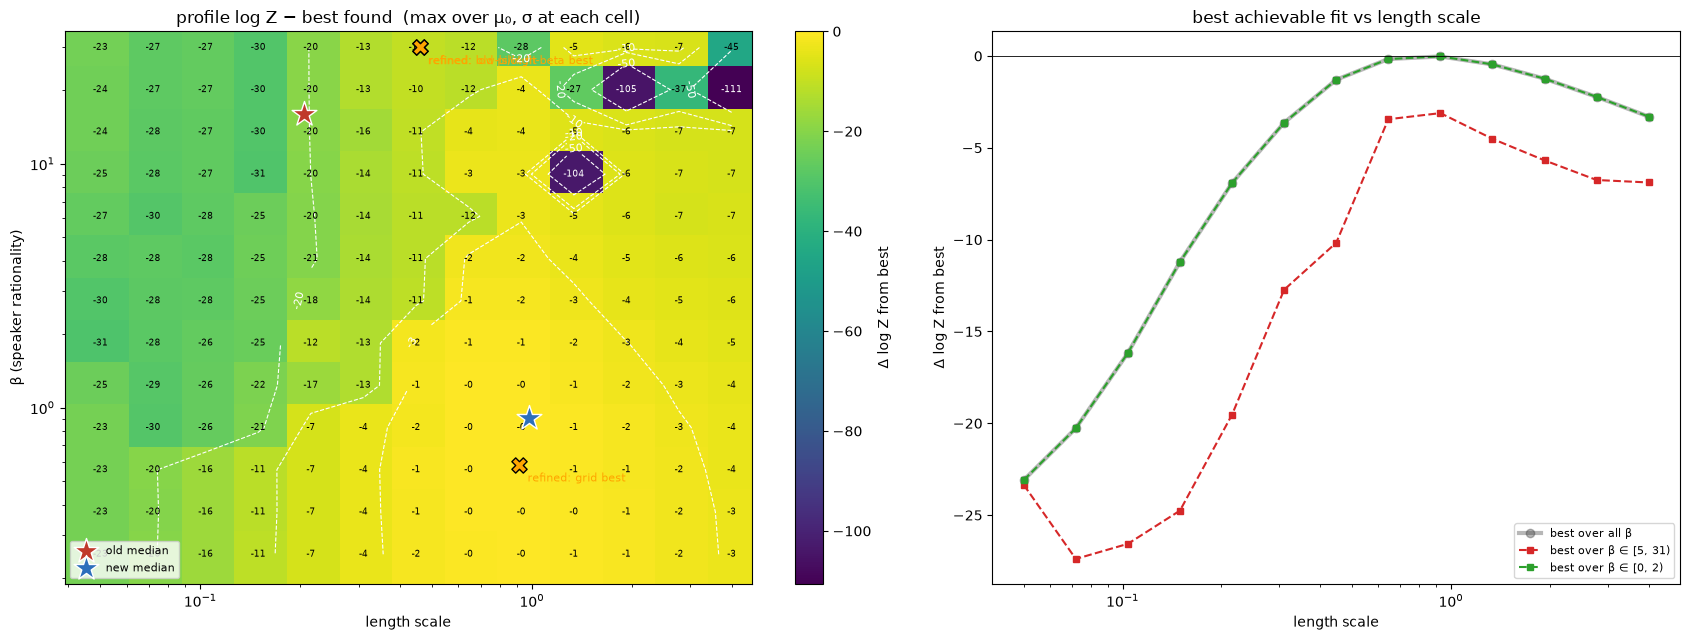

,start,start ls,start β,ls,mu_0,sigma,β,log Z,log joint
0,grid best,0.928,0.555,0.915,0.072,0.596,0.582,989.350,987.496
1,low-ls/high-beta best,0.310,30.000,0.458,-0.170,0.339,30.000,979.222,975.450
2,old pilot fit,0.205,16.035,0.461,-0.174,0.340,29.998,979.223,975.455
3,(new VBMC median),NaN,NaN,0.978,0.006,0.526,0.907,988.751,987.386


best grid cell overall:          Δ = -0.0
best grid cell ls<0.4 & β>5:     Δ = -12.7


In [10]:
PROFILE_NPZ = 'results/study9-fit/profile-ls-beta.npz'
if not os.path.exists(PROFILE_NPZ):
    print(f"{PROFILE_NPZ} not found -- run `python profile_study9_ls_beta.py` (~35 min), then re-run this cell.")
else:
    prof = np.load(PROFILE_NPZ, allow_pickle=True)
    LSg, Bg, LLg = prof['ls_grid'], prof['beta_grid'], prof['ll']
    ll_max = max(np.nanmax(LLg), prof['refine_ll'].max())
    D = LLg - ll_max                                       # 0 = best found anywhere

    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1.25, 1]})
    ax = axes[0]
    im = ax.pcolormesh(LSg, Bg, D.T, shading='nearest', cmap='viridis', vmin=max(D.min(), -120), vmax=0)
    cs = ax.contour(LSg, Bg, D.T, levels=[-50, -20, -10, -3], colors='w', linewidths=0.8)
    ax.clabel(cs, fmt='%d', fontsize=8)
    for i in range(len(LSg)):
        for k in range(len(Bg)):
            ax.text(LSg[i], Bg[k], f"{D[i, k]:.0f}", ha='center', va='center', fontsize=6.5,
                    color='w' if D[i, k] < -60 else 'k')
    for m in THETA:
        ax.scatter(THETA[m][0], THETA[m][3], marker='*', s=350, color=COLORS[m], edgecolor='w', zorder=5,
                   label=f'{m} median')
    for tag, th in zip(prof['refine_tags'], prof['refine_theta']):
        ax.scatter(th[0], th[3], marker='X', s=120, color='orange', edgecolor='k', zorder=6)
        ax.annotate(f"refined: {tag}", (th[0], th[3]), fontsize=8, xytext=(6, -12), textcoords='offset points',
                    color='orange')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('length scale'); ax.set_ylabel('β (speaker rationality)')
    ax.set_title('profile log Z − best found  (max over μ₀, σ at each cell)')
    fig.colorbar(im, ax=ax, label='Δ log Z from best')
    ax.legend(loc='lower left', fontsize=8)

    ax = axes[1]
    ax.plot(LSg, np.nanmax(D, axis=1), 'o-', color='0.2', lw=3, alpha=0.35, label='best over all β')
    for b_lo, b_hi, col in [(5, 31, 'C3'), (0, 2, 'C2')]:
        sel = (Bg >= b_lo) & (Bg < b_hi)
        ax.plot(LSg, np.nanmax(D[:, sel], axis=1), 's--', color=col, ms=4,
                label=f'best over β ∈ [{b_lo}, {b_hi})')
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xscale('log'); ax.set_xlabel('length scale'); ax.set_ylabel('Δ log Z from best')
    ax.set_title('best achievable fit vs length scale'); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    ref = pd.DataFrame({'start': prof['refine_tags'],
                        'start ls': prof['refine_start'][:, 0], 'start β': prof['refine_start'][:, 3],
                        'ls': prof['refine_theta'][:, 0], 'mu_0': prof['refine_theta'][:, 1],
                        'sigma': prof['refine_theta'][:, 2], 'β': prof['refine_theta'][:, 3],
                        'log Z': prof['refine_ll'], 'log joint': prof['refine_ll'] + prof['refine_log_prior']})
    ref.loc[len(ref)] = ['(new VBMC median)', np.nan, np.nan, *THETA['new'],
                         summary.loc['log Z (joint)', 'new'], summary.loc['log joint (logZ + prior)', 'new']]
    display(ref.round(3))

    corner = (LSg[:, None] < 0.4) & (Bg[None, :] > 5)
    print(f"best grid cell overall:          Δ = {np.nanmax(D):+.1f}")
    print(f"best grid cell ls<0.4 & β>5:     Δ = {np.nanmax(np.where(corner, D, -np.inf)):+.1f}")